# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [81]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [82]:
# GIVEN: load the data
df = pd.read_csv("wholesale_sample.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1,1,4181,10024,26577,1979,9194,1151
1,2,3,3346,4848,14310,1155,2666,1768
2,2,3,3687,8096,10837,870,7701,1345
3,1,2,3008,6327,16926,1032,5303,1582
4,2,3,4704,13163,20537,1507,3073,1267


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [83]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[spend_cols].describe()
df.shape
df.info()
df[spend_cols].describe



<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           150 non-null    int64
 1   Region            150 non-null    int64
 2   Fresh             150 non-null    int64
 3   Milk              150 non-null    int64
 4   Grocery           150 non-null    int64
 5   Frozen            150 non-null    int64
 6   Detergents_Paper  150 non-null    int64
 7   Delicassen        150 non-null    int64
dtypes: int64(8)
memory usage: 9.5 KB


<bound method DataFrame.describe of      Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0     4181  10024    26577    1979              9194        1151
1     3346   4848    14310    1155              2666        1768
2     3687   8096    10837     870              7701        1345
3     3008   6327    16926    1032              5303        1582
4     4704  13163    20537    1507              3073        1267
..     ...    ...      ...     ...               ...         ...
145  14775   3565     3126    7288               975        3142
146   2354   5189     8428    1400              4435        1253
147   4048   5646    22334    1594              5118        1874
148   4483   1521     4793    3779              1222        1008
149  20657   4727     2843    7355               519         979

[150 rows x 6 columns]>

## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [84]:
# TODO: build X from the spend columns and scale it
X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)




## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

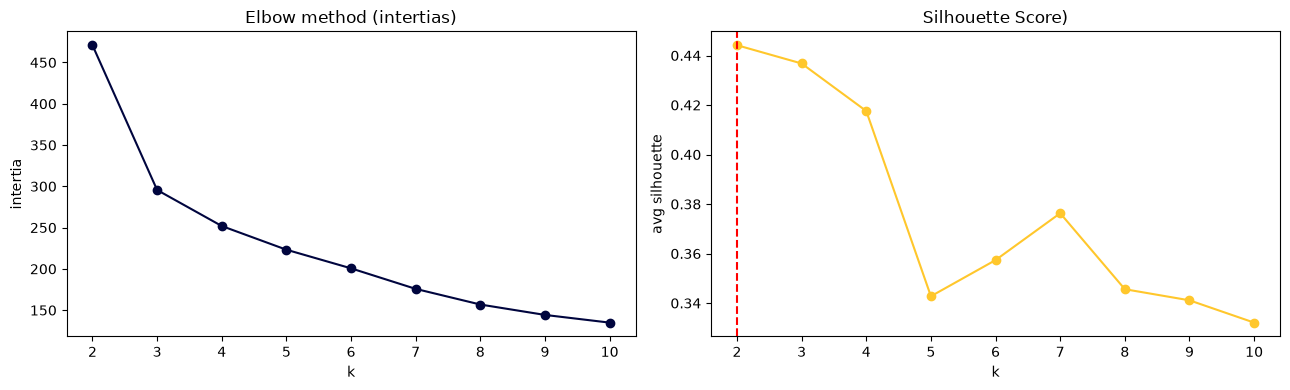

In [85]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
ks = range(2, 11)
intertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    intertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils
fig, ax = plt.subplots(1, 2, figsize =(13, 4))
ax[0].plot(list(ks), intertias, "o-", color=ETSU_NAVY)
ax[0].set_title("Elbow method (intertias)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("intertia")

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("Silhouette Score)"); ax[1].set_xlabel("k"); ax[1].set_ylabel("avg silhouette")

# retrieving the best k
best_k = list(ks)[int(np.argmax(sils))] 
ax[1].axvline(best_k, color="red", linestyle="--")
plt.tight_layout(); plt.show()



**Your chosen k and why:**

My chosen k is 2 because it is the highest score in the silhouette score.

## Step 5: Fit k-means with your chosen k

In [86]:
# TODO: fit KMeans at your chosen k and attach the labels to df
YOUR_K=2
kmeans = KMeans(n_clusters=YOUR_K, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_



## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

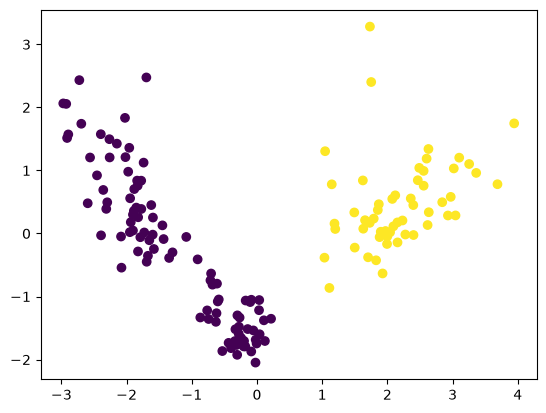

In [87]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
pcs = PCA(n_components=2).fit_transform(Xs)
plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])




## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [88]:
# TODO: build a profile table of per-cluster averages
df.groupby("cluster")[spend_cols].mean().round(0)
df["cluster"].value_counts() 
profile = df.groupby("cluster").agg(
    customers=("Channel", "count"),
    avg_fresh=("Fresh", "mean"),
    avg_milk=("Milk", "mean"),
    avg_grocery=("Grocery", "mean"),
    avg_frozen=("Frozen", "mean"),
    avg_detergents_paper=("Detergents_Paper", "mean"),
    avg_delicassen=("Delicassen", "mean"),
).round(1)
profile



,customers,avg_fresh,avg_milk,avg_grocery,avg_frozen,avg_detergents_paper,avg_delicassen
cluster,,,,,,,
0,95,13871.7,2996.1,3372.9,3869.7,1055.1,1895.1
1,55,4127.6,9614.1,15824.2,1545.1,6310.1,1660.0


## Step 8: Findings

1. **How many clusters did you choose, and why?** (what the elbow and silhouette showed)
I chose two clusters because the silhoutte showed that was the best k number.
2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?
The first cluster was a big fresh retailer, spending on average 13,871. Which is the category they spent the most on. They also spent more on frozen, spending 3869 on average.

The second cluster was mostly spending money on groceries. Spending on average 15,824. They were buying a lot of milk, coming in at 9,614 on everage. Also a lot on detergent, spending 6,310.

3. **One action per segment:** what should the distributor do differently for each group?

For the first cluster they should make sure theres a lot of fresh stuff out, since that is what they like. For the other group make sure there is plenty of groceries, and everyday household needs.

4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?
I would like to use a different k next time, maybe make the clusters even more specific.
## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing